# Failure diagnosis

**Final project · Intelligent museum guide** · issue #7

Deliverable 2, part 2: what went wrong, why, how we fixed it, and how much the fix brought, with every claim backed
by a number or a figure. Most numbers come from the other notebooks, through their `results/*.json` files, so
this notebook must run **after** `baseline`, `mlp`, `resnet` and `monitoring` (it also loads the weights
`results/resnet.pt` saved by the ResNet notebook).

1. **Overfitting** of the MLP, reproduced without any regularisation, then fixed.
2. **Learning rate and activation**: the failures seen in the monitoring notebook.
3. **Per-class accuracy**: which styles each model recognises, and which ones it confuses.
4. **Misclassified paintings** of the ResNet, and what its confidence tells us.
5. **Summary table** (`results/diagnosis.csv`): symptom, diagnosis, fix and measured effect, ready for the slides.

**How this notebook is organised**

- From `src/`: `load_splits`, `FlipDataset` and `split_indices` (data), `MLP` and `ResNetClassifier` (models),
  `fit`, `plot_history` and `RESULTS_DIR`.
- It reads `results/baseline.json`, `mlp.json`, `resnet.json` and `monitoring.json` (the dictionary `results`),
  and the weights `results/resnet.pt`.
- Defined here: `at(history, epoch)`, the validation accuracy, train-validation gap and validation loss of a
  history at a given epoch.
- Each part appends rows to the list `summary` (failure, symptom, diagnosis, fix, measured effect); the last cell
  writes it to `results/diagnosis.csv`.

In [1]:
import csv
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

sys.path.append("..")
from src.data import DATA_DIR, FlipDataset, load_splits, split_indices
from src.models import MLP, ResNetClassifier
from src.plots import plot_history
from src.train import RESULTS_DIR, fit

np.random.seed(0)
torch.manual_seed(0)
loss_fn = nn.CrossEntropyLoss()
# the numbers measured by the other notebooks
results = {name: json.load(open(RESULTS_DIR / f"{name}.json")) for name in ["baseline", "mlp", "resnet", "monitoring"]}
summary = []          # one row per failure: the table of Part 5

## 1. Overfitting: a big network on few images

The chosen MLP has 2.1 million weights for 1 050 training paintings. We train it for 60 epochs **without any
regularisation and without early stopping**, three times (three seeds), and look at the last epoch. Then we
apply the fixes of Session 6: early stopping (the weights of the epoch with the lowest validation loss), and
early stopping with dropout 0.5 and random flips. The train accuracy is the one measured during each epoch.

train 1050 images | per class {'Baroque': 210, 'Cubism': 210, 'Impressionism': 210, 'Pop_Art': 210, 'Ukiyo_e': 210}
val    225 images | per class {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}
test   225 images | per class {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}


no regularisation, last epoch      val acc 0.366 | train - val gap 0.629 | val loss 3.85
early stopping                     val acc 0.384 | train - val gap 0.105 | val loss 1.45
early stopping + dropout + flips   val acc 0.399 | train - val gap 0.078 | val loss 1.42


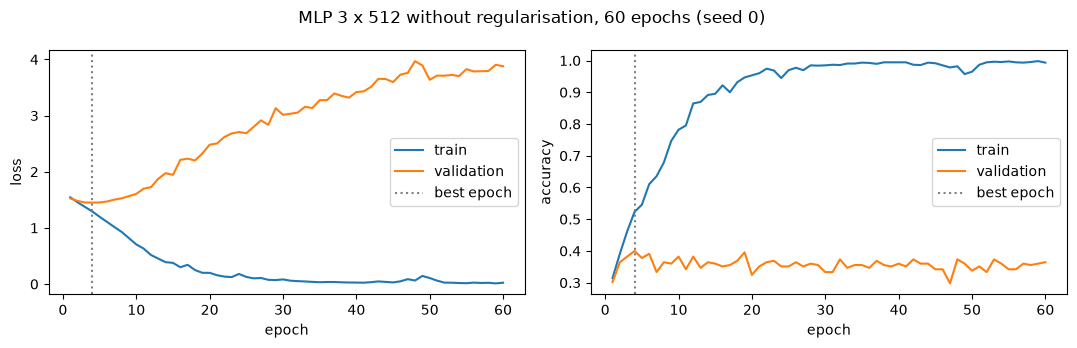

In [2]:
splits, classes = load_splits("train", size=32)
X_train, y_train = splits["train"]
plain_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
flip_loader = DataLoader(FlipDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(*splits["val"]), batch_size=256)
N_IN = 3 * 32 * 32


def at(history, epoch):
    """Validation accuracy, train - validation gap and validation loss at a given epoch (1-based)."""
    i = epoch - 1
    return {"val_acc": history["val_acc"][i], "gap": history["train_acc"][i] - history["val_acc"][i],
            "val_loss": history["val_loss"][i]}


runs = {"no regularisation, last epoch": [], "early stopping": [], "early stopping + dropout + flips": []}
for seed in [0, 1, 2]:
    torch.manual_seed(seed)
    model = MLP(N_IN, width=512, depth=3)
    h = fit(model, plain_loader, val_loader, loss_fn, torch.optim.Adam(model.parameters(), lr=1e-4),
            n_epochs=60, seed=seed, verbose=False)
    if seed == 0:
        history_overfit = h
    # one run gives both rows: its last epoch (no early stopping) and its best epoch (early stopping)
    runs["no regularisation, last epoch"].append(at(h, len(h["val_loss"])))
    runs["early stopping"].append(at(h, h["best_epoch"]))

    torch.manual_seed(seed)
    model = MLP(N_IN, width=512, depth=3, dropout=0.5)
    h = fit(model, flip_loader, val_loader, loss_fn, torch.optim.Adam(model.parameters(), lr=1e-4),
            n_epochs=100, patience=10, seed=seed, verbose=False)
    runs["early stopping + dropout + flips"].append(at(h, h["best_epoch"]))

overfit = {name: {key: float(np.mean([r[key] for r in rs])) for key in rs[0]} for name, rs in runs.items()}
for name, r in overfit.items():
    print(f"{name:34s} val acc {r['val_acc']:.3f} | train - val gap {r['gap']:.3f} | val loss {r['val_loss']:.2f}")
plot_history(history_overfit, "MLP 3 x 512 without regularisation, 60 epochs (seed 0)",
             RESULTS_DIR / "diagnosis_overfitting.png")

In [3]:
no_reg, fixed = overfit["no regularisation, last epoch"], overfit["early stopping + dropout + flips"]
summary.append({
    "failure": "Overfitting (MLP)",
    "symptom": f"train accuracy {history_overfit['train_acc'][-1]:.2f} vs validation {history_overfit['val_acc'][-1]:.2f} "
               f"after 60 epochs; validation loss lowest at epoch {history_overfit['best_epoch']}, then up to "
               f"{history_overfit['val_loss'][-1]:.1f}",
    "diagnosis": "2.1 million weights for 1 050 paintings: the network learns the training set by heart",
    "fix": "early stopping + dropout 0.5 + random flips",
    "effect": f"validation accuracy {no_reg['val_acc']:.3f} -> {fixed['val_acc']:.3f}, "
              f"train - validation gap {no_reg['gap']:.2f} -> {fixed['gap']:.2f} (3 seeds)",
})

**What we see.** Without regularisation, the MLP learns the training set by heart: train accuracy 0.99,
and a validation loss that is lowest at epoch 4 and then rises to 3.9 while the validation accuracy stays at
0.36. Overfitting costs little accuracy here, but a lot of confidence: the network becomes sure of wrong answers
(the validation loss is 3.85, against ln 5 = 1.61 for a network that knows nothing). Early stopping alone brings
the gap from 0.63 down to 0.11 and the validation loss back to 1.45. Adding dropout and flips gains another 1.5
points (0.399) and the smallest gap (0.08). The accuracy barely moves, because the limit of the MLP is its input,
not only overfitting (Part 3).

## 2. Learning rate and activation

These failures were measured in the monitoring notebook (`results/monitoring.json`) and in the MLP notebook
(`results/mlp.json`); we only gather the numbers here.

In [4]:
lr = results["monitoring"]["learning_rate"]
good, high, low = lr["lr = 0.0001"], lr["lr = 0.01"], lr["lr = 1e-06"]
grads, acts = results["monitoring"]["gradient_norms"], results["monitoring"]["activations"]
relu, sigmoid = results["mlp"]["activations"]["ReLU"], results["mlp"]["activations"]["Sigmoid"]

summary.append({
    "failure": "Learning rate too high (1e-2)",
    "symptom": f"training loss {high['train_loss_epoch_1']:.1f} after the first epoch, then a validation loss "
               "that oscillates",
    "diagnosis": "the steps of Adam are too large to settle into a minimum",
    "fix": "learning rate 1e-4",
    "effect": f"validation accuracy {high['val_acc_at_min']:.3f} -> {good['val_acc_at_min']:.3f}",
})
summary.append({
    "failure": "Learning rate too low (1e-6)",
    "symptom": f"training loss {low['train_loss_epoch_1']:.2f} -> {low['train_loss_epoch_30']:.2f} in 30 epochs",
    "diagnosis": "the steps are too small: the network stays near its random initialisation",
    "fix": "learning rate 1e-4",
    "effect": f"validation accuracy {low['val_acc_at_min']:.3f} -> {good['val_acc_at_min']:.3f}",
})
summary.append({
    "failure": "Vanishing gradient (sigmoid)",
    "symptom": f"best epoch {sigmoid['best_epoch']:.1f} instead of {relu['best_epoch']:.1f} with ReLU",
    "diagnosis": f"first-layer gradient {grads['Sigmoid']['last_over_first']:.0f} times smaller than the output layer; "
                 f"{acts['Sigmoid'][0]['saturated_outputs']:.0%} saturated outputs in the first layer",
    "fix": "ReLU",
    "effect": f"validation accuracy {sigmoid['val_acc']:.3f} -> {relu['val_acc']:.3f}, "
              f"best epoch {sigmoid['best_epoch']:.1f} -> {relu['best_epoch']:.1f}",
})
for row in summary[1:]:
    print(f"{row['failure']:30s} {row['effect']}")

Learning rate too high (1e-2)  validation accuracy 0.342 -> 0.400
Learning rate too low (1e-6)   validation accuracy 0.311 -> 0.400
Vanishing gradient (sigmoid)   validation accuracy 0.363 -> 0.384, best epoch 17.7 -> 3.7


## 3. Per-class accuracy

For each model, the accuracy on the 45 test paintings of each style (the diagonal of its confusion matrix
divided by 45). The baselines, the MLP and the ResNet were all evaluated on the same test images.

                                 Baroque        Cubism Impressionism       Pop_Art       Ukiyo_e
LogReg pixels                       0.71          0.18          0.13          0.51          0.31
LogReg colour histograms            0.51          0.11          0.27          0.44          0.64
MLP                                 0.62          0.22          0.33          0.47          0.51
LogReg ResNet features              0.69          0.78          0.82          0.76          0.80
ResNet-18 fine-tuned                0.76          0.67          0.82          0.73          1.00


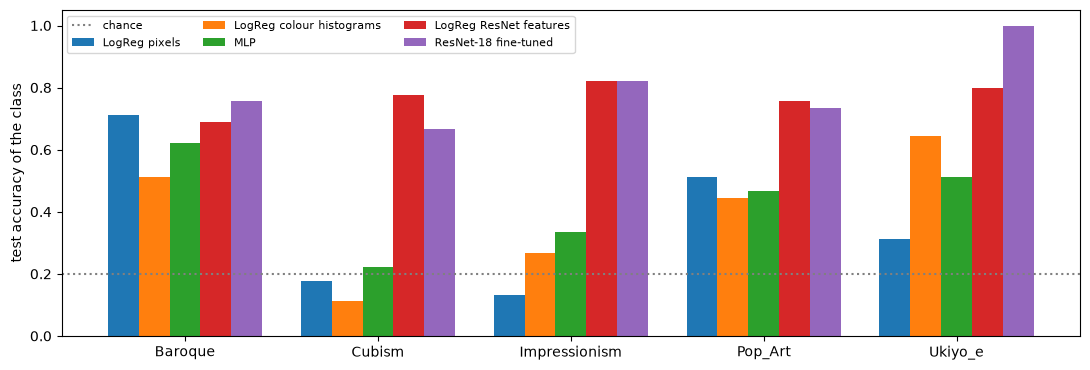

largest confusions of the ResNet (true -> predicted): Impressionism -> Baroque (7), Cubism -> Pop_Art (7), Baroque -> Impressionism (7), Pop_Art -> Ukiyo_e (5)


In [5]:
models = {
    "LogReg pixels": results["baseline"]["logreg_pixels"],
    "LogReg colour histograms": results["baseline"]["logreg_histograms"],
    "MLP": results["mlp"],
    "LogReg ResNet features": results["resnet"]["logreg_features"],
    "ResNet-18 fine-tuned": results["resnet"]["finetuned"],
}
per_class = {}
for name, r in models.items():
    cm = np.array(r["confusion_matrix"])
    per_class[name] = cm.diagonal() / cm.sum(axis=1)   # correct predictions of each style / its 45 paintings

print(f"{'':26s}" + "".join(f"{c:>14s}" for c in classes))
for name, acc in per_class.items():
    print(f"{name:26s}" + "".join(f"{a:14.2f}" for a in acc))

fig, ax = plt.subplots(figsize=(11, 3.8))
width = 0.8 / len(per_class)
for k, (name, acc) in enumerate(per_class.items()):
    ax.bar(np.arange(len(classes)) + k * width, acc, width, label=name)
ax.set_xticks(np.arange(len(classes)) + 0.4 - width / 2, classes)
ax.set_ylabel("test accuracy of the class"); ax.axhline(0.2, color="grey", linestyle=":", label="chance")
ax.legend(fontsize=8, ncol=3); ax.set_ylim(0, 1.05)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "diagnosis_per_class.png", dpi=120)
plt.show()

cm = np.array(models["ResNet-18 fine-tuned"]["confusion_matrix"])
# off-diagonal cells: (count, true style, predicted style)
off = [(cm[i, j], classes[i], classes[j]) for i in range(len(classes)) for j in range(len(classes)) if i != j]
print("largest confusions of the ResNet (true -> predicted):",
      ", ".join(f"{t} -> {p} ({n})" for n, t, p in sorted(off, reverse=True)[:4]))

**What we see.** The three classical models and the MLP share the same profile: they recognise Baroque
(dark tones) and partly Pop Art and Ukiyo-e (saturated or flat colours), but stay near chance on Cubism and
Impressionism, whose difference is in brushwork and shapes, not colour. This is why regularising the MLP cannot
help much: its input does not contain the right information in a usable form. The two models built on ResNet
features lift every style, most of all Cubism (0.22 → 0.67 to 0.78) and Impressionism (0.33 → 0.82). The
fine-tuned network recognises every Ukiyo-e; the logistic regression on features is better on Cubism. The largest
remaining confusions, Baroque ↔ Impressionism and Cubism → Pop Art, are pairs that a human visitor could also
hesitate on.

In [6]:
mlp_cm = np.array(results["mlp"]["confusion_matrix"])
cubism = classes.index("Cubism")
summary.append({
    "failure": "Raw pixels are the wrong input (MLP)",
    "symptom": f"regularisation does not lift validation accuracy above about 0.40; Cubism "
               f"{mlp_cm[cubism, cubism]} / 45",
    "diagnosis": "one weight per pixel: no notion of texture or shape; same per-class profile as the classical "
                 "models (Baroque recognised, Cubism and Impressionism not)",
    "fix": "features of a ResNet-18 pretrained on ImageNet",
    "effect": f"test accuracy {results['mlp']['accuracy']:.3f} -> {results['resnet']['finetuned']['accuracy']:.3f}; "
              f"Cubism {mlp_cm[cubism, cubism]} -> {cm[cubism, cubism]} / 45",
})
h = results["resnet"]["finetuned"]["history"]
best = results["resnet"]["finetuned"]["best_epoch"]
summary.append({
    "failure": "Fine-tuning overfits fast (ResNet)",
    "symptom": f"train accuracy {max(h['train_acc']):.2f} after {int(np.argmax(h['train_acc'])) + 1} epochs; "
               f"validation loss lowest at epoch {best}",
    "diagnosis": "11 million weights adapted on 1 050 paintings",
    "fix": "early stopping, learning rate 1e-4 for the pretrained weights, ImageNet batch-norm statistics",
    "effect": f"validation loss {h['val_loss'][-1]:.2f} at the last epoch -> {h['val_loss'][best - 1]:.2f} at the "
              f"best one; validation accuracy {h['val_acc'][-1]:.3f} -> {h['val_acc'][best - 1]:.3f}",
})

## 4. Misclassified paintings

We reload the fine-tuned ResNet (`results/resnet.pt`) and predict the test set on the CPU. The softmax of its
output gives a confidence for each prediction. We show the 12 errors made with the highest confidence, with the
artist and the genre of the painting when the metadata of WikiArt knows them.

46 errors out of 225; mean confidence 0.87 when right, 0.70 when wrong


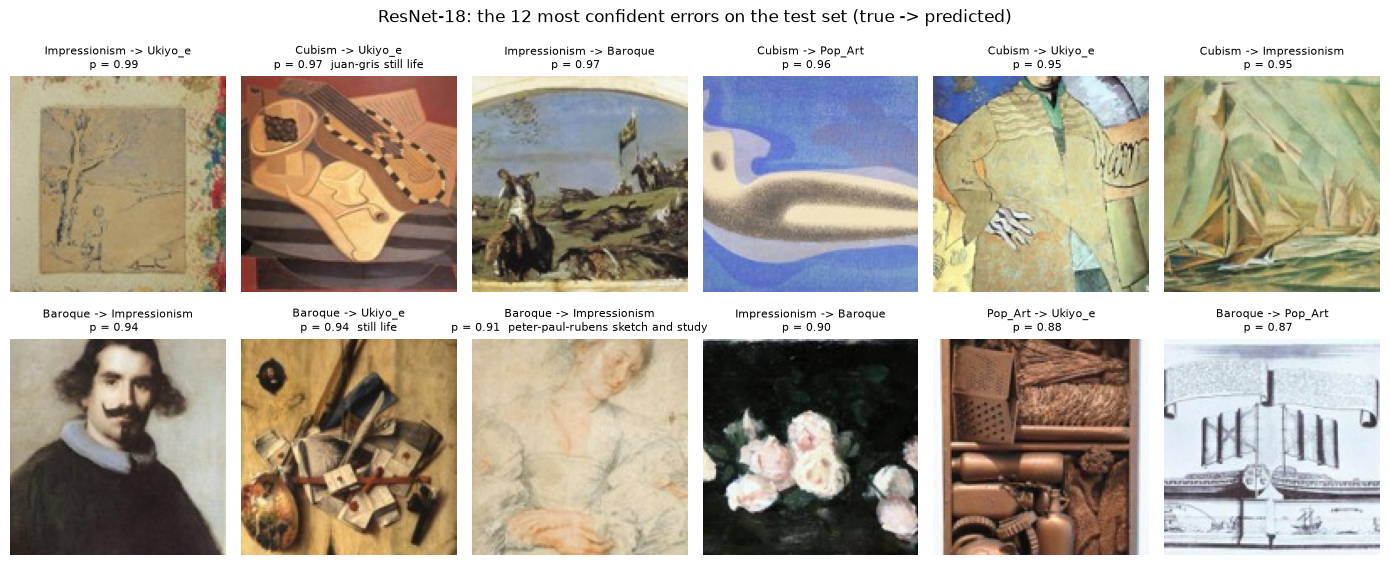

In [7]:
model = ResNetClassifier()
model.load_state_dict(torch.load(RESULTS_DIR / "resnet.pt", map_location="cpu"))
model.eval()
X_test, y_test = load_splits("imagenet", size=128, verbose=False)[0]["test"]
images = load_splits("none", size=128, verbose=False)[0]["test"][0]          # same paintings, pixels in [0, 1]
with torch.no_grad():
    proba = torch.softmax(model(X_test), dim=1)       # scores -> probabilities that sum to 1
confidence, pred = proba.max(dim=1)                   # the highest probability is the confidence

folder = datasets.ImageFolder(DATA_DIR)
_, _, test_idx = split_indices(torch.tensor(folder.targets))   # the same split as load_splits
metadata = {row["path"]: row for row in csv.DictReader(open(DATA_DIR / "metadata.csv"))}
test_meta = [metadata[Path(folder.samples[i][0]).relative_to(DATA_DIR).as_posix()] for i in test_idx]
assert all(m["label"] == classes[c] for m, c in zip(test_meta, y_test)), "metadata and test set do not match"

wrong = torch.nonzero(pred != y_test).flatten()
wrong = wrong[confidence[wrong].argsort(descending=True)]      # most confident errors first
print(f"{len(wrong)} errors out of {len(y_test)}; mean confidence {confidence[pred == y_test].mean():.2f} "
      f"when right, {confidence[pred != y_test].mean():.2f} when wrong")

fig, axes = plt.subplots(2, 6, figsize=(14, 6))
for ax, i in zip(axes.flat, wrong[:12].tolist()):
    m = test_meta[i]
    who = " ".join(x for x in [m["artist"], m["genre"]] if not x.startswith("Unknown")).replace("_", " ")
    ax.imshow(images[i].permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"{classes[y_test[i]]} -> {classes[pred[i]]}\np = {confidence[i]:.2f}  {who}", fontsize=8)
fig.suptitle("ResNet-18: the 12 most confident errors on the test set (true -> predicted)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "diagnosis_errors.png", dpi=120)
plt.show()

A guide that is wrong with confidence is worse than a guide that says it is not sure. If the kiosk only
names a style when the confidence is above a threshold, how many paintings does it still answer, and how often is
it right on those?

In [8]:
thresholds = {}
for t in [0.0, 0.5, 0.7, 0.9]:
    answered = confidence >= t             # the guide only names a style above the threshold
    thresholds[t] = {"answered": answered.float().mean().item(),
                     "accuracy": (pred[answered] == y_test[answered]).float().mean().item()}
    print(f"confidence >= {t:.1f}: answers {thresholds[t]['answered']:.0%} of the paintings, "
          f"accuracy {thresholds[t]['accuracy']:.3f} on those")

confidence >= 0.0: answers 100% of the paintings, accuracy 0.796 on those
confidence >= 0.5: answers 94% of the paintings, accuracy 0.816 on those
confidence >= 0.7: answers 77% of the paintings, accuracy 0.861 on those
confidence >= 0.9: answers 51% of the paintings, accuracy 0.922 on those


**What we see.**

- **Atypical works.** A third of the most confident errors (4 of 12) are not paintings in the usual sense: a pencil
  drawing, a chalk sketch by Rubens, an engraving, a photo of an assemblage. Paper tones and thin lines are what
  the network learned for Ukiyo-e, which are woodblock prints.
- **Understandable cues.** The other errors follow cues that a person would also use: roses on a dark background
  are called Baroque, and a portrait painted with free brushwork is called Impressionism.
- **Errors are less confident.** The mean confidence is 0.70 when the network is wrong, against 0.87 when it is
  right. If the kiosk only names a style above a confidence of 0.7, it answers 77 % of the paintings and is right
  on 86 % of them, instead of 80 % on all. For the other paintings it can say that it is not sure, which is better
  than telling the story of the wrong movement.

The test set is used here to analyse the final model, not to choose it; a threshold for production should be set
on the validation set.

In [9]:
top = sorted(off, reverse=True)[:3]
summary.append({
    "failure": "Remaining confusions (ResNet)",
    "symptom": ", ".join(f"{t} -> {p} ({n})" for n, t, p in top),
    "diagnosis": f"atypical works (4 of the 12 most confident errors are drawings, an engraving or a photo of an "
                 f"object), dark backgrounds read as Baroque, loose brushwork as Impressionism; errors are less "
                 f"confident ({confidence[pred != y_test].mean():.2f} vs {confidence[pred == y_test].mean():.2f})",
    "fix": "not fixed; the guide can answer only above a confidence threshold",
    "effect": f"threshold 0.7: {thresholds[0.7]['answered']:.0%} of the paintings answered, accuracy "
              f"{thresholds[0.7]['accuracy']:.3f} (instead of {thresholds[0.0]['accuracy']:.3f} on all)",
})

## 5. Summary table

One row per failure, saved in `results/diagnosis.csv` for the slides.

In [10]:
with open(RESULTS_DIR / "diagnosis.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["failure", "symptom", "diagnosis", "fix", "effect"])
    writer.writeheader()
    writer.writerows(summary)

for row in summary:
    print(f"## {row['failure']}")
    for key in ["symptom", "diagnosis", "fix", "effect"]:
        print(f"   {key:9s} {row[key]}")

## Overfitting (MLP)
   symptom   train accuracy 0.99 vs validation 0.36 after 60 epochs; validation loss lowest at epoch 4, then up to 3.9
   diagnosis 2.1 million weights for 1 050 paintings: the network learns the training set by heart
   fix       early stopping + dropout 0.5 + random flips
   effect    validation accuracy 0.366 -> 0.399, train - validation gap 0.63 -> 0.08 (3 seeds)
## Learning rate too high (1e-2)
   symptom   training loss 10.3 after the first epoch, then a validation loss that oscillates
   diagnosis the steps of Adam are too large to settle into a minimum
   fix       learning rate 1e-4
   effect    validation accuracy 0.342 -> 0.400
## Learning rate too low (1e-6)
   symptom   training loss 1.61 -> 1.54 in 30 epochs
   diagnosis the steps are too small: the network stays near its random initialisation
   fix       learning rate 1e-4
   effect    validation accuracy 0.311 -> 0.400
## Vanishing gradient (sigmoid)
   symptom   best epoch 17.7 instead of 3.7 with

## What we take from it

- **Every training failure was detected and fixed by a measured change.**
  - Overfitting: seen on the learning curves, fixed by early stopping, dropout and flips.
  - Learning rate too high or too low: seen on the loss curves, fixed by the learning rate.
  - Vanishing gradient: seen on the gradient norms, fixed by ReLU.

  Each fix is worth a few points of validation accuracy, or a much better calibrated network.
- **The decisive failure is the input.** No setting of the MLP goes past 0.40 on validation. Pretrained
  convolutional features reach 0.80 on the test set, and they lift precisely the styles defined by brushwork and
  shapes.
- **The remaining errors of the ResNet can be explained and detected.** They are mostly atypical works, and its
  confidence is lower on them. This gives the director a product option: answer only when the network is
  confident.

The table above is saved in `results/diagnosis.csv`; the figures are `results/diagnosis_overfitting.png`,
`results/diagnosis_per_class.png` and `results/diagnosis_errors.png`.